# 01 · 真实数据、特征与 ItemCF
## Goal
沿着真实 Python 代码看一次推荐：数据文件 → 因果历史 → 用户特征 → ItemCF 得分 → 已看过滤。

本 Notebook 默认只读已有数据和基线，不重新下载、不改原流计算 lab，也不更新模型。用 **Shift+Enter** 逐格执行；左侧文件浏览器可以打开并编辑 `reclab/*.py`。

## Setup
内核选择 **Recommendation Lab (Python 3.12)**。输入来自本项目的 `data/processed/events.parquet`、`manifest.json` 和 `artifacts/baselines/`；数据源为 [Retailrocket](https://www.kaggle.com/retailrocket/ecommerce-dataset/home)。

当前任务是训练截止之后的**暖商品、新物品交互召回**。浏览是行为，不是推荐曝光；未交互不等于曝光未点击。

In [2]:
from pathlib import Path
import sys
import inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Code


PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents]
               if (p / "reclab/models.py").exists())
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
from reclab.data import Dataset
from reclab.paths import ARTIFACTS, PROCESSED, read_json


plt.rcParams.update({"figure.figsize": (9, 3.8), "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": "#182b2b", "text.color": "#182b2b",
    "axes.facecolor": "white", "figure.facecolor": "white",
    "grid.color": "#d4ddda", "axes.axisbelow": True})
dataset = Dataset()
print("Project:", PROJECT)
print("Dataset version:", dataset.manifest["dataset_version"])
print("Python:", sys.executable)
assert Path(sys.executable).parent == PROJECT / ".venv/bin", "请选择 Recommendation Lab 内核"

Project: /Users/lizuolin/local/recommendation-lab
Dataset version: 2772cab0aca8cb81
Python: /Users/lizuolin/local/recommendation-lab/.venv/bin/python


## Steps
### 1. 先看文件和实际时间边界
这些数字从冻结 manifest 读取，和网页是同一份数据。

In [2]:
m = dataset.manifest
display(pd.Series({k: m[k] for k in ["raw_events", "cohort_users", "catalog_items", "cohort_events", "feature_version"]}, name="value").to_frame())
boundaries = pd.Series({"start": m["start_ms"], "train_end": m["train_end_ms"], "valid_end": m["valid_end_ms"], "end": m["end_ms"]})
display(pd.to_datetime(boundaries, unit="ms", utc=True).to_frame("UTC boundary"))
display(dataset.events.head(5))

,value
raw_events,2756101
cohort_users,6734
catalog_items,5000
cohort_events,265884
feature_version,history-id-v1


,UTC boundary
start,2015-05-03 03:00:04.384000+00:00
train_end,2015-08-07 17:23:52.766000+00:00
valid_end,2015-08-28 10:11:50.277000+00:00
end,2015-09-18 02:59:47.788000+00:00


,timestamp,visitorid,event,itemid,transactionid,split,item_idx,user_idx,weight,event_id
0,1430622124584,1346730,view,252280,NaN,train,0,6434,1.0,40
1,1430622325414,1222911,view,278143,NaN,train,0,5847,1.0,87
2,1430622876445,1359701,view,173766,NaN,train,0,6498,1.0,219
3,1430623120795,122517,view,75694,NaN,train,0,529,1.0,295
4,1430623150639,122517,view,443197,NaN,train,0,529,1.0,305


### 2. 用 SQL 检查 Parquet
DuckDB 只在内存里查询，不启动任何容器。`item_idx=0` 表示不在训练词表中的物品。

In [3]:
import duckdb
with duckdb.connect(":memory:") as con:
    split_summary = con.execute("""
        SELECT split, count(*) AS events,
               count(DISTINCT visitorid) AS users,
               count(*) FILTER (WHERE item_idx = 0) AS oov_events
        FROM read_parquet(?) GROUP BY split ORDER BY split
    """, [str(PROCESSED / "events.parquet")]).df()
display(split_summary)

,split,events,users,oov_events
0,test,10350,472,7692
1,train,240095,6734,119080
2,valid,15439,617,10859


### 3. 选一个用户，查看真正送入模型的历史
修改 `USER_POSITION` 或 `HISTORY_WINDOW` 后，重跑以下几格。类目是用于解释的元数据，当前双塔没有把它作为输入。

In [4]:
USER_POSITION = 0
HISTORY_WINDOW = 20
TOP_K = 10
eligible, audit = dataset.evaluation("valid", 1000)
user_idx = list(eligible)[USER_POSITION]
history = dataset.histories[user_idx]
user_events = dataset.train[dataset.train.user_idx == user_idx].sort_values("timestamp", kind="stable")
print("User ID:", dataset.users[user_idx], "User index:", user_idx)
print("Training-only history:", history[-HISTORY_WINDOW:])
preview = user_events.tail(HISTORY_WINDOW)[["timestamp", "event", "itemid", "item_idx"]].copy()
preview["timestamp"] = pd.to_datetime(preview.timestamp, unit="ms", utc=True)
display(preview)
assert user_events.timestamp.max() < m["train_end_ms"]

User ID: 1055524 User index: 5071
Training-only history: [4008, 2088, 2633, 3949, 211, 211, 2913]


,timestamp,event,itemid,item_idx
51317,2015-05-23 13:54:45.097000+00:00,view,374092,4008
51319,2015-05-23 13:56:22.761000+00:00,view,200231,2088
51320,2015-05-23 13:57:32.977000+00:00,view,248327,2633
51321,2015-05-23 13:58:58.224000+00:00,view,367664,3949
52462,2015-05-23 23:38:32.172000+00:00,view,21253,211
52472,2015-05-23 23:40:07.466000+00:00,addtocart,21253,211
209735,2015-07-23 21:57:59.118000+00:00,view,272770,2913


### 4. 从真实样本倒查历史
正目标是首次交互的新商品，历史必须严格早于它。先读函数源码，再检查一条实际样本。

In [5]:
display(Code(inspect.getsource(Dataset.examples), language="python"))
sample_users, sample_history, sample_targets, sample_times = dataset.examples(HISTORY_WINDOW)
selected = np.flatnonzero(sample_users == user_idx)
assert len(selected), "当前用户没有可用训练样本，请换 USER_POSITION"
j = int(selected[0])
context = sample_history[j][sample_history[j] != 0].tolist()
target = int(sample_targets[j])
prior = user_events[user_events.timestamp < sample_times[j]]
display(pd.DataFrame([{"user_idx": user_idx, "history": context,
    "target_item_idx": target, "target_time_utc": pd.to_datetime(sample_times[j], unit="ms", utc=True)}]))
assert context == prior.item_idx.astype(int).tail(HISTORY_WINDOW).tolist()
assert target not in set(prior.item_idx)

def examples(self, history_len=20):
        users, histories, targets, times = [], [], [], []
        for user, group in self.train.groupby("user_idx", sort=True):
            past, seen, last_time = [], set(), -1
            for row in group.sort_values("timestamp", kind="stable").itertuples():
                item = int(row.item_idx)
                if (
                    len(seen) >= 2
                    and item not in seen
                    and last_time < int(row.timestamp)
                ):
                    h = past[-history_len:]
                    users.append(int(user))
                    histories.append([0] * (history_len - len(h)) + h)
                    targets.append(item)
                    times.append(int(row.timestamp))
                past.append(item)
                seen.add(item)
                last_time = int(row.timestamp)
        return (
            np.array(users, dtype=np.int64),
            np.array(histories, dtype=np.int64),
            np.array(targets, dtype=np.int64),
            np.array(times, dtype=np.int64),
        )

,user_idx,history,target_item_idx,target_time_utc
0,5071,"[4008, 2088]",2633,2015-05-23 13:57:32.977000+00:00


### 5. 看 ItemCF 源码并计算推荐
这里使用实际保存的邻居矩阵。当前变体加入了活跃用户惩罚，保留每个商品 Top100 邻居；打分使用最近 50 次行为的衰减权重。

In [6]:
from scipy import sparse
from reclab.retrieval import itemcf, cf_scores, topk
display(Code(inspect.getsource(itemcf), language="python"))
similarity = sparse.load_npz(ARTIFACTS / "baselines/itemcf.npz")
scores = cf_scores(similarity, history, dataset.n_items)
recommendations = topk(scores, TOP_K, dataset.seen[user_idx])
display(pd.DataFrame([{**dataset.items[i-1], "itemcf_score": float(scores[i])}
                      for i in recommendations]))
assert not set(recommendations) & dataset.seen[user_idx]

def itemcf(dataset):
    pairs = dataset.train[["user_idx", "item_idx"]].drop_duplicates()
    matrix = sparse.csr_matrix(
        (np.ones(len(pairs), dtype=np.float32), (pairs.user_idx, pairs.item_idx)),
        shape=(dataset.n_users, dataset.n_items),
    )
    # Inverse user activity reduces extremely active users' co-occurrence contribution.
    activity = np.asarray(matrix.sum(1)).ravel()
    weighted = sparse.diags(1 / np.log1p(np.maximum(activity, 1))) @ matrix
    co = (matrix.T @ weighted).tocsr()
    frequency = np.asarray(matrix.sum(0)).ravel()
    norm = sparse.diags(1 / np.sqrt(np.maximum(frequency, 1)))
    sim = (norm @ co @ norm).tocsr()
    sim.setdiag(0)
    sim.eliminate_zeros()
    # Keep 100 neighbors per item, bounded memory and easy inspection.
    for i in range(sim.shape[0]):
        a, b = sim.indptr[i : i + 2]
        if b - a > 100:
            loc = np.argpartition(sim.data[a:b], -100)[:-100]
            sim.data[a + loc] = 0
    sim.eliminate_zeros()
    return sim

,item_idx,item_id,category,category_asof_ms,train_events,itemcf_score
0,3720,348157,1666,1433646000000,101,0.145335
1,2727,257040,683,1433041200000,1324,0.138386
2,991,94296,1565,1431226800000,90,0.112878
3,4051,378045,1666,1435460400000,224,0.111876
4,722,69974,818,1433041200000,249,0.109628
5,3794,354733,23,1431226800000,82,0.108164
6,3402,317899,1666,1431226800000,87,0.103384
7,4619,432152,683,1431226800000,382,0.101446
8,3596,337512,316,1431226800000,83,0.099587
9,4101,382751,683,1435460400000,460,0.099382


### 6. 一个分数是怎样累加出来的？
对第一个候选，把每条历史的贡献展开，并核对它们的和。

In [7]:
chosen_item = recommendations[0]
recent = history[-50:]
recency_weights = np.geomspace(0.2, 1.0, len(recent))
contributions = pd.DataFrame([{"history_item_idx": i,
    "history_item_id": dataset.items[i-1]["item_id"],
    "similarity": float(similarity[i, chosen_item]), "weight": float(w),
    "contribution": float(similarity[i, chosen_item]) * w}
    for i, w in zip(recent, recency_weights)])
display(contributions.sort_values("contribution", ascending=False).head(10))
print("Sum of contributions:", contributions.contribution.sum())
print("Saved scorer output:", float(scores[chosen_item]))
assert np.isclose(contributions.contribution.sum(), scores[chosen_item], atol=1e-6)

,history_item_idx,history_item_id,similarity,weight,contribution
5,211,21253,0.100419,0.764724,0.076793
4,211,21253,0.100419,0.584804,0.058725
2,2633,248327,0.028706,0.341995,0.009817
0,4008,374092,0.000000,0.200000,0.000000
1,2088,200231,0.000000,0.261532,0.000000
3,3949,367664,0.000000,0.447214,0.000000
6,2913,272770,0.000000,1.000000,0.000000


Sum of contributions: 0.14533540791386457
Saved scorer output: 0.14533540606498718


### 7. 对照已有基线结果
同一验证窗口、全训练词表、训练期已看过滤。分数只覆盖当前可评估的活跃暖启动用户。

,Recall@20,NDCG@20,users
model,,,
popular,0.020754,0.017910,339
itemcf,0.145167,0.079874,339


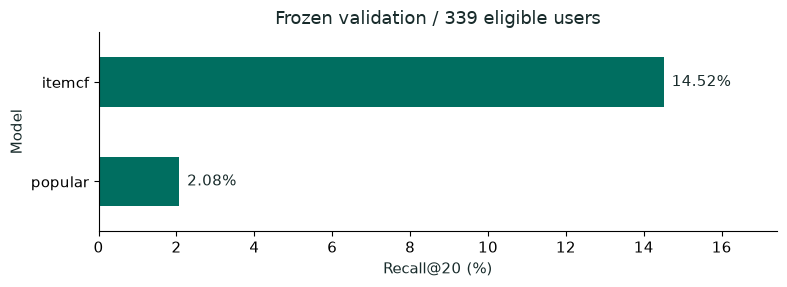

In [8]:
baseline = read_json(ARTIFACTS / "baselines/metrics.json")
result = pd.DataFrame([{"model": name, "Recall@20": row["metrics"]["recall@20"],
    "NDCG@20": row["metrics"]["ndcg@20"], "users": row["audit"]["evaluated_users"]}
    for name, row in baseline["models"].items()]).set_index("model")
display(result)
ax = (result["Recall@20"] * 100).plot.barh(color="#006e60", figsize=(8, 3))
ax.set(xlabel="Recall@20 (%)", ylabel="Model",
       title=f"Frozen validation / {int(result.users.iloc[0])} eligible users")
ax.set_xlim(left=0)
for y, value in enumerate(result["Recall@20"] * 100):
    ax.text(value + 0.2, y, f"{value:.2f}%", va="center")
ax.set_xlim(0, max(result["Recall@20"] * 100) * 1.2)
plt.tight_layout(); plt.show()

## Checks
上面的断言验证了时间边界、因果样本、已看过滤，以及 ItemCF 分数的逐条贡献。原始精确数值仍保留在表格里。

## Next Steps
先预测：把历史截成最近 3 个商品，哪些候选应该改变？将 `cf_scores(similarity, history[-3:], ...)` 作为单用户反事实对照；它不是重新训练后的离线指标。

接着打开 `02_TwoTower_HandsOn.ipynb`。讲义对应：ItemCF、离散特征处理、双塔样本。